### Visualisation data

In [3]:
import pandas as pd
from pathlib import Path as p

DIR = p(r'C:\\Users\\pc\\Desktop\\M2 BDIO\\LLMs\\Decetction-Persuation\\data')

df_1b_train = pd.read_json(DIR / "task1B_train.jsonl", lines=True, encoding="utf-8")
df_1b_dev   = pd.read_json(DIR / "task1B_dev.jsonl", lines=True, encoding="utf-8")
df_1b_test  = pd.read_json(DIR / "task1B_test.jsonl", lines=True, encoding="utf-8")

In [4]:
df_1b_dev.head(10)

,id,text,labels,type
0,MIS_2265-eurl_03_021,وقال كذلك إنه يتعين على المجلس أيضا أن يطالب ا...,[Loaded_Language],paragraph
1,MIS_2905-eurl_06_012,ويسعى حلفاء نافالني لتحدي الأحزاب الموالية للك...,[Loaded_Language],paragraph
2,MIS_73-curl_04_002,ونسبت الوكالة شبه الرسمية للنائب أحمد حمزة قول...,[no_technique],paragraph
3,MIS_1303-eurl_03_008,كما دعت للحيطة من تلك المخططات الإسرائيلية الق...,"[Name_Calling-Labeling, Appeal_to_Fear-Prejudi...",paragraph
4,MIS_134-curl_04_009,ووفقا للنظام الكفالة فإن صاحب العمل يعتبر من ا...,[Loaded_Language],paragraph
5,MIS_1934-curl_06_004,ولا تزال محطات البنزين في سورية تعاني من ازدحا...,[Loaded_Language],paragraph
6,MIS_1520-eurl_02_021,وكشف تقرير مسرب عن الأمم المتحدة في مايو/أيار ...,"[Loaded_Language, Name_Calling-Labeling, Exagg...",paragraph
7,AFP_674-curl_03_001,دمرت السلطات الصينية آلاف المساجد في شينجيانغ،...,"[Loaded_Language, Exaggeration-Minimisation]",paragraph
8,MIS_2766-eurl_03_004,وأدخلت قوات الاحتلال الأمريكي خلال الأشهر القل...,"[Loaded_Language, Name_Calling-Labeling, Quest...",paragraph
9,AFP_458-eurl_02_020,غير أنه بالبحث، تبين أن الفيديو يعود لعام 2014...,[Loaded_Language],paragraph


### label distribution

#### Train

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_label_distribution(df: pd.DataFrame, label_col: str = "labels", treat_no_technique_as_zero: bool = True):

    def count_labels(lbl_list):

        if not isinstance(lbl_list, (list, set, tuple)):
            return 0 if pd.isna(lbl_list) else 1
        if treat_no_technique_as_zero:
            return len([l for l in lbl_list if l != "no_technique"])
        return len(lbl_list)
    counts_series = df[label_col].apply(count_labels)
    freq = counts_series.value_counts().sort_index()
    total = len(counts_series)
    
    
    plt.figure(figsize=(9, 5.5))
    ax = sns.barplot(x=freq.index, y=freq.values, palette="crest")

    for p in ax.patches:
        height = p.get_height()
        pct = (height / total) * 100
        ax.annotate(
            f"{int(height)}\n({pct:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 4),
            textcoords="offset points"
        )
    plt.title("Distribution of Number of Labels per Sample", fontsize=13, fontweight="bold", pad=15)
    plt.xlabel("Number of Techniques Assigned (0 = No Technique)", fontsize=11)
    plt.ylabel("Number of Samples", fontsize=11)
    plt.ylim(0, max(freq.values) * 1.18)  
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


C:\Users\pc\AppData\Local\Temp\ipykernel_7368\3292217957.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")


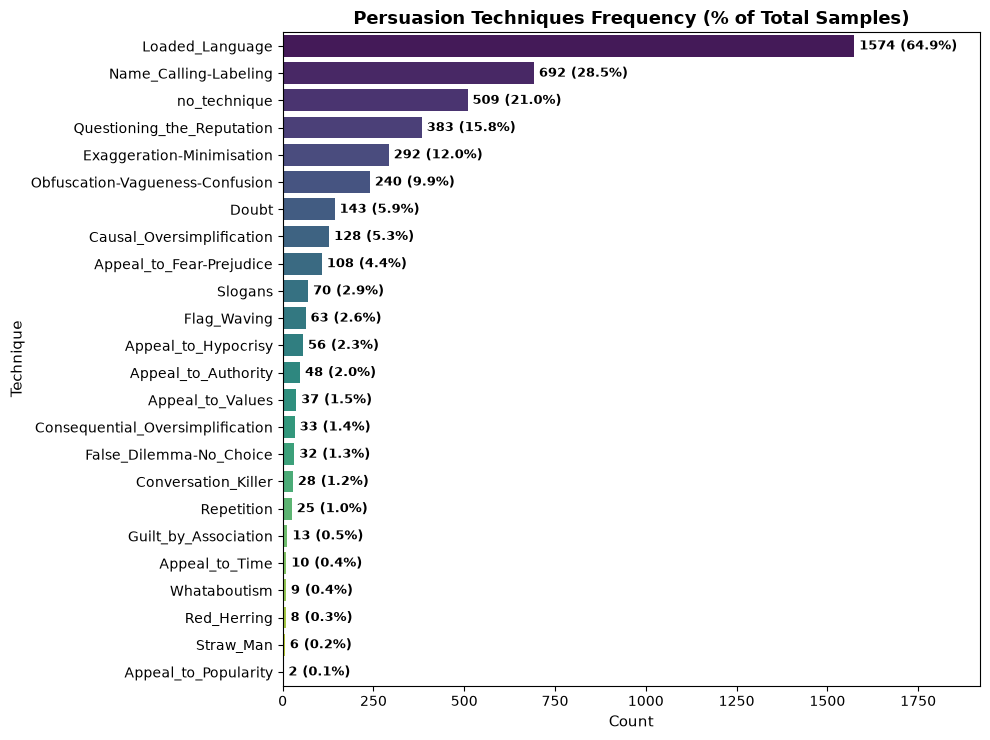

In [6]:
exploded = df_1b_train["labels"].explode()
technique_counts = exploded.value_counts()
total_samples = len(df_1b_train)

plt.figure(figsize=(10, 7.5))
ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")

for p in ax.patches:
    width = p.get_width()
    pct = (width / total_samples) * 100
    ax.annotate(
        f" {int(width)} ({pct:.1f}%)",
        (width, p.get_y() + p.get_height() / 2.0),
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Persuasion Techniques Frequency (% of Total Samples)", fontsize=13, fontweight="bold")
plt.xlabel("Count", fontsize=11)
plt.ylabel("Technique", fontsize=11)
plt.xlim(0, max(technique_counts.values) * 1.22)  
plt.tight_layout()
plt.show()

#### val

C:\Users\pc\AppData\Local\Temp\ipykernel_7368\2627764104.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")


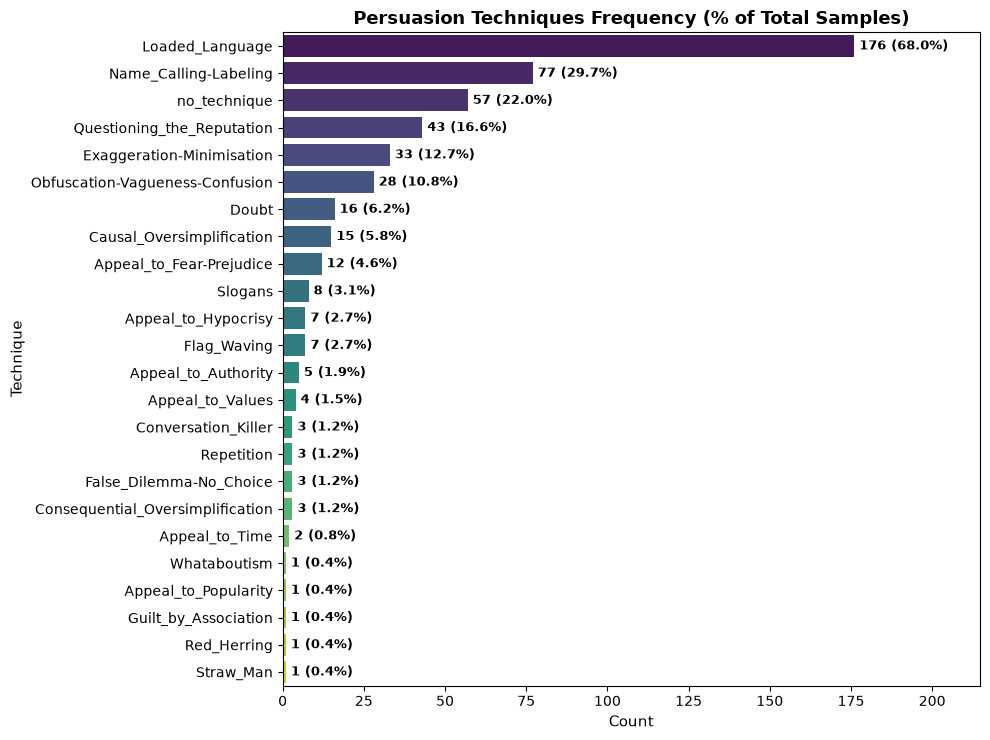

In [7]:
exploded = df_1b_dev["labels"].explode()
technique_counts = exploded.value_counts()
total_samples = len(df_1b_dev)

plt.figure(figsize=(10, 7.5))
ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")

for p in ax.patches:
    width = p.get_width()
    pct = (width / total_samples) * 100
    ax.annotate(
        f" {int(width)} ({pct:.1f}%)",
        (width, p.get_y() + p.get_height() / 2.0),
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Persuasion Techniques Frequency (% of Total Samples)", fontsize=13, fontweight="bold")
plt.xlabel("Count", fontsize=11)
plt.ylabel("Technique", fontsize=11)
plt.xlim(0, max(technique_counts.values) * 1.22)  
plt.tight_layout()
plt.show()

#### Test

C:\Users\pc\AppData\Local\Temp\ipykernel_7368\1706270621.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")


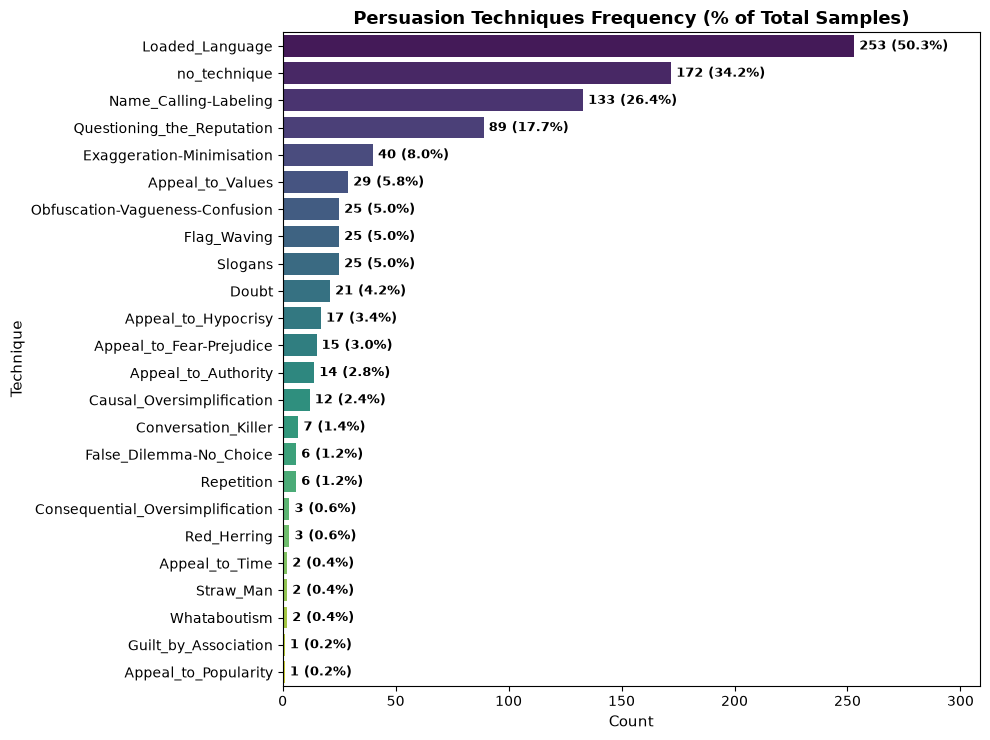

In [8]:
exploded = df_1b_test["labels"].explode()
technique_counts = exploded.value_counts()
total_samples = len(df_1b_test)

plt.figure(figsize=(10, 7.5))
ax = sns.barplot(y=technique_counts.index, x=technique_counts.values, palette="viridis")

for p in ax.patches:
    width = p.get_width()
    pct = (width / total_samples) * 100
    ax.annotate(
        f" {int(width)} ({pct:.1f}%)",
        (width, p.get_y() + p.get_height() / 2.0),
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Persuasion Techniques Frequency (% of Total Samples)", fontsize=13, fontweight="bold")
plt.xlabel("Count", fontsize=11)
plt.ylabel("Technique", fontsize=11)
plt.xlim(0, max(technique_counts.values) * 1.22)  
plt.tight_layout()
plt.show()

### labels numbering %

In [9]:
def get_label_count_distribution(df: pd.DataFrame, label_col: str = "labels", treat_no_technique_as_zero: bool = True) -> pd.DataFrame:
    def count_labels(label_list):
        if not isinstance(label_list, (list, set, tuple)):
            return 0 if pd.isna(label_list) else 1
        
        if treat_no_technique_as_zero:
            # Filter out 'no_technique' placeholder
            actual_labels = [lbl for lbl in label_list if lbl != "no_technique"]
            return len(actual_labels)
        return len(label_list)
    # 1. Count labels per row
    counts_per_row = df[label_col].apply(count_labels)
    
    # 2. Compute frequency and proportions
    counts = counts_per_row.value_counts().sort_index()
    percentages = (counts_per_row.value_counts(normalize=True).sort_index() * 100).round(2)
    cumulative_pct = percentages.cumsum().round(2)
    
    # 3. Build summary DataFrame
    summary_df = pd.DataFrame({
        "Number of Labels": counts.index,
        "Sample Count": counts.values,
        "Portion (%)": percentages.values,
        "Cumulative (%)": cumulative_pct.values
    }).set_index("Number of Labels")
    
    # Print formatted output
    total = len(df)
    print(f"Total Samples Analyzed: {total}\n" + "="*45)
    for num_labels, row in summary_df.iterrows():
        label_text = "label" if num_labels == 1 else "labels"
        print(f"• {num_labels} {label_text}: {int(row['Sample Count'])} samples ({row['Portion (%)']}%)")
    print("="*45)
    
    return summary_df

#### Train

In [10]:
# 1. Treating ['no_technique'] as 0 techniques:
summary = get_label_count_distribution(df_1b_train, label_col="labels", treat_no_technique_as_zero=True)
# View the DataFrame table:
summary

Total Samples Analyzed: 2427
• 0 labels: 509 samples (20.97%)
• 1 label: 618 samples (25.46%)
• 2 labels: 734 samples (30.24%)
• 3 labels: 389 samples (16.03%)
• 4 labels: 146 samples (6.02%)
• 5 labels: 25 samples (1.03%)
• 6 labels: 4 samples (0.16%)
• 7 labels: 2 samples (0.08%)


,Sample Count,Portion (%),Cumulative (%)
Number of Labels,,,
0,509,20.97,20.97
1,618,25.46,46.43
2,734,30.24,76.67
3,389,16.03,92.70
4,146,6.02,98.72
5,25,1.03,99.75
6,4,0.16,99.91
7,2,0.08,99.99


In [11]:
import pandas as pd

def show_unlabeled_samples(
    df: pd.DataFrame, 
    n: int = 5, 
    label_col: str = "labels", 
    text_col: str = "text", 
    random_state: int = 42
) -> pd.DataFrame:
    
    def is_no_label(lbl_list):
        if not isinstance(lbl_list, (list, set, tuple)):
            return pd.isna(lbl_list)
        # Check if list is empty or only contains 'no_technique'
        actual_labels = [l for l in lbl_list if l != "no_technique"]
        return len(actual_labels) == 0

    # 1. Filter rows with no techniques
    unlabeled_df = df[df[label_col].apply(is_no_label)]
    
    total_unlabeled = len(unlabeled_df)
    sample_size = min(n, total_unlabeled)
    
    # 2. Sample n rows
    sampled_df = unlabeled_df.sample(n=sample_size, random_state=random_state)
    
    # 3. Print in a readable format
    print(f"Found {total_unlabeled} samples with NO persuasion techniques ({total_unlabeled/len(df)*100:.2f}% of data).")
    print(f"Displaying {sample_size} random examples:\n" + "=" * 80)
    
    for i, (_, row) in enumerate(sampled_df.iterrows(), 1):
        doc_id = row.get("id", "N/A")
        doc_type = row.get("type", "N/A")
        labels = row.get(label_col)
        text = row.get(text_col, "")
        
        print(f"[{i}] ID: {doc_id} | Type: {doc_type} | Labels: {labels}")
        print(f"Text:\n{text}")
        print("-" * 80)
        
    return sampled_df

In [12]:
samples = show_unlabeled_samples(df_1b_train, n=5)

Found 509 samples with NO persuasion techniques (20.97% of data).
Displaying 5 random examples:
[1] ID: MIS_1093-curl_01_013 | Type: paragraph | Labels: ['no_technique']
Text:
يذكر أن التكلفة منخفضة كذلك حيث يكلف المصباح الواحد نحو 13 يورو، تصف جيفري هذه التكنولوجيا بالبسيطة والآمنة للغاية، وتقول "تكلف أجهزتنا حوالي 12 جنيهًا إسترلينيًا، لذا فإن التكنولوجيا متاحة بشكل كبير للناس".
--------------------------------------------------------------------------------
[2] ID: FAT_1313-eurl_04_015 | Type: paragraph | Labels: ['no_technique']
Text:
ويقال إنه عرض الرسوم الكاريكاتيرية للنبي محمد أثناء حديثه عن قضية شارلي إيبدو، ونصح الطلاب المسلمين بمغادرة الغرفة إذا اعتقدوا أنهم قد يشعروا بالتعرض للإهانة.
--------------------------------------------------------------------------------
[3] ID: MIS_1141-curl_05_001 | Type: paragraph | Labels: ['no_technique']
Text:
كشفت صحيفة “الإسبانيول” الإسبانية، إن المغرب قدم عرضا للولايات المتحدة الأمريكية لإنشاء قاعدة عسكرية بالقصر الصغير ضواحي ميناء طنجة الم

In [13]:
df_1b_train["clean_labels"] =df_1b_train["labels"].apply(lambda lbls: [l for l in lbls if l != "no_technique"])
df_1b_train["num_labels"] =df_1b_train["clean_labels"].apply(len)
df_1b_train["has_loaded_language"] =df_1b_train["clean_labels"].apply(lambda lbls: "Loaded_Language" in lbls)

Overall Dataset: 1574 / 2427 (64.85%) contain Loaded_Language
Among Persuasive texts (1+ labels): 1574 / 1918 (82.06%) contain Loaded_Language

=== Breakdown by Label Count ===
            total_samples  with_loaded_language  pct_loaded_language
num_labels                                                          
0                     509                     0                 0.00
1                     618                   391                63.27
2                     734                   650                88.56
3                     389                   368                94.60
4                     146                   134                91.78
5                      25                    25               100.00
6                       4                     4               100.00
7                       2                     2               100.00


C:\Users\pc\AppData\Local\Temp\ipykernel_7368\1785645102.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


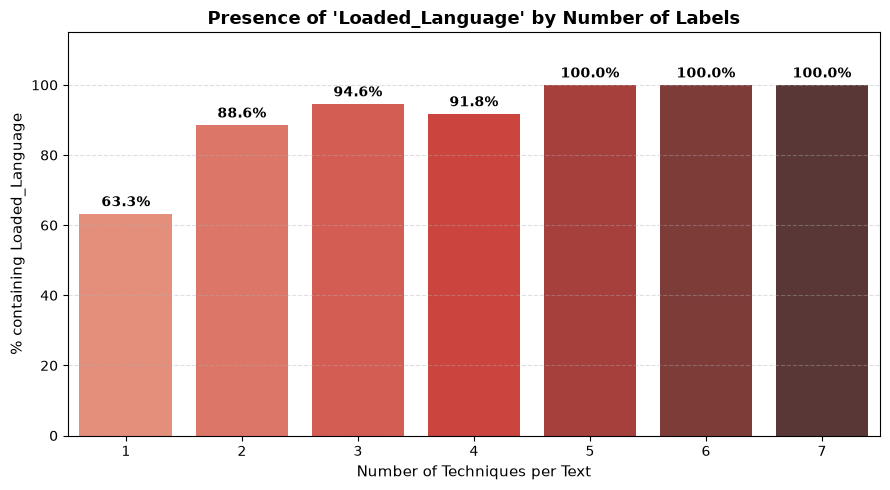

In [14]:
total_all = len(df_1b_train)
total_ll = df_1b_train["has_loaded_language"].sum()
persuasive_df = df_1b_train[df_1b_train["num_labels"] >= 1]
total_persuasive = len(persuasive_df)
print(f"Overall Dataset: {total_ll} / {total_all} ({total_ll / total_all * 100:.2f}%) contain Loaded_Language")
print(f"Among Persuasive texts (1+ labels): {total_ll} / {total_persuasive} ({total_ll / total_persuasive * 100:.2f}%) contain Loaded_Language\n")
# 3. Breakdown Table by Label Count
breakdown = df_1b_train.groupby("num_labels").agg(
    total_samples=("has_loaded_language", "count"),
    with_loaded_language=("has_loaded_language", "sum")
)
breakdown["pct_loaded_language"] = (breakdown["with_loaded_language"] / breakdown["total_samples"] * 100).round(2)
print("=== Breakdown by Label Count ===")
print(breakdown)
# 4. Visualization: Presence of Loaded Language as number of labels increases
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=breakdown.index[1:],  # Exclude 0 labels for clearer view of persuasive texts
    y=breakdown["pct_loaded_language"].iloc[1:], 
    palette="Reds_d"
)
plt.title("Presence of 'Loaded_Language' by Number of Labels", fontsize=13, fontweight="bold")
plt.xlabel("Number of Techniques per Text", fontsize=11)
plt.ylabel("% containing Loaded_Language", fontsize=11)
plt.ylim(0, 115)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.1f}%",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                xytext=(0, 3), textcoords="offset points")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
def plot_text_type_distribution(datasets: pd.DataFrame, title_prefix: str = "Task 1B"):

    # 1. Normalize input to a dictionary of DataFrames
    data_dict = {}
    if isinstance(datasets, str):
        data_dict = {"Dataset": pd.read_json(datasets, lines=True)}
    elif isinstance(datasets, pd.DataFrame):
        data_dict = {"Dataset": datasets}
    elif isinstance(datasets, dict):
        for name, data in datasets.items():
            if isinstance(data, str):
                data_dict[name] = pd.read_json(data, lines=True)
            elif isinstance(data, pd.DataFrame):
                data_dict[name] = data
            else:
                raise ValueError(
                    f"Unsupported data type for {name}: {type(data)}"
                )
    else:
        raise ValueError(f"Unsupported input type: {type(datasets)}")

    # 2. Setup Plot Canvas
    num_plots = len(data_dict)
    fig, axes = plt.subplots(
        nrows=1,
        ncols=num_plots,
        figsize=(6 * num_plots, 5.5),
        dpi=110,
        squeeze=False,
    )
    axes = axes.flatten()

    # Modern color palette: Paragraph (Deep Slate Blue), Tweet (Twitter/Vibrant Cyan-Blue)
    color_map = {
        "paragraph": "#2b5c8f",
        "tweet": "#1da1f2",
    }
    fallback_colors = ["#2b5c8f", "#1da1f2", "#f27935", "#36b37e"]

    # 3. Render Donut Charts
    for idx, (split_name, df) in enumerate(data_dict.items()):
        ax = axes[idx]
        counts = df["type"].value_counts()
        labels = counts.index.tolist()
        values = counts.values
        total = values.sum()

        colors = [color_map.get(label.lower(), fallback_colors[i % len(fallback_colors)]) for i, label in enumerate(labels)]

        # Custom autopct label formatting: "64.9%\n(1,574)"
        def autopct_format(pct):
            count = int(np.round(pct * total / 100.0))
            return f"{pct:.1f}%\n({count:,})"

        wedges, texts, autotexts = ax.pie(
            values,
            labels=[l.capitalize() for l in labels],
            autopct=autopct_format,
            pctdistance=0.72,
            startangle=140,
            colors=colors,
            wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2.5),
            textprops=dict(fontsize=11, fontweight="medium"),
        )

        for autotext in autotexts:
            autotext.set_fontsize(10)
            autotext.set_fontweight("bold")
            autotext.set_color("white")

        # Inner ring text showing total sample count
        ax.text(
            0,
            0,
            f"Total\n{total:,}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="#2d3748",
        )

        ax.set_title(
            f"{split_name}\n({title_prefix})",
            fontsize=13,
            fontweight="bold",
            pad=14,
            color="#1a202c",
        )

    plt.suptitle(
        "Text Genre Distribution: Paragraphs vs. Tweets",
        fontsize=15,
        fontweight="bold",
        y=1.02,
        color="#0f172a",
    )
    plt.tight_layout()
    plt.show()


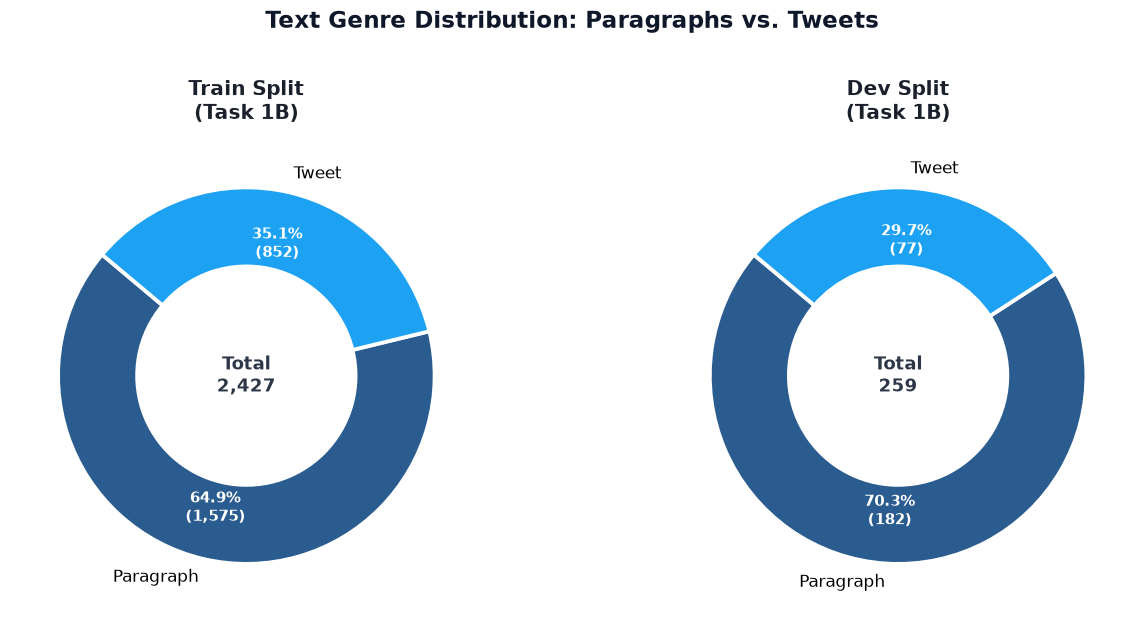

In [ ]:
plot_text_type_distribution({
    "Train Split": "../../../data/task1B_train.jsonl",
    "Dev Split": "../../../data/task1B_dev.jsonl"
})

In [24]:

def explore_text_lengths(
    data: pd.DataFrame | str,
    text_col: str = "text",
    type_col: str = "type",
    plot: bool = True,
):

    # 1. Load data if file path is provided
    if isinstance(data, str):
        df = pd.read_json(data, lines=True)
    else:
        df = data.copy()

    # 2. Compute Length Metrics
    df["char_len"] = df[text_col].astype(str).str.len()
    df["word_len"] = df[text_col].astype(str).str.split().str.len()

    # 3. Aggregate Statistics Function
    def get_stats(series):
        return {
            "Min": int(series.min()),
            "Max": int(series.max()),
            "Mean (Avg)": round(series.mean(), 2),
            "Median": round(series.median(), 2),
            "Std Dev": round(series.std(), 2),
        }

    # Build summary rows
    summary_data = []

    # Overall stats
    overall_words = get_stats(df["word_len"])
    overall_chars = get_stats(df["char_len"])
    summary_data.append(
        {"Scope": "Overall", "Metric": "Words (Count)", **overall_words}
    )
    summary_data.append(
        {"Scope": "Overall", "Metric": "Characters (Len)", **overall_chars}
    )

    # Breakdown by text type (tweet / paragraph) if column exists
    if type_col in df.columns:
        for genre, group in df.groupby(type_col):
            w_stats = get_stats(group["word_len"])
            c_stats = get_stats(group["char_len"])
            summary_data.append(
                {"Scope": genre.capitalize(), "Metric": "Words (Count)", **w_stats}
            )
            summary_data.append(
                {
                    "Scope": genre.capitalize(),
                    "Metric": "Characters (Len)",
                    **c_stats,
                }
            )

    summary_df = (
        pd.DataFrame(summary_data)
        .set_index(["Scope", "Metric"])
        .sort_index(level=0)
    )

    # 4. Display Formatted Table
    print(f"\n📊 Total Samples Analyzed: {len(df):,}")
    display(summary_df)

    # 5. Optional Distribution Plots
    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=105)

        # Plot 1: Word Count Distribution (KDE / Hist)
        if type_col in df.columns:
            sns.histplot(
                data=df,
                x="word_len",
                hue=type_col,
                kde=True,
                ax=axes[0],
                palette=["#2b5c8f", "#1da1f2"],
                bins=35,
            )
        else:
            sns.histplot(
                data=df,
                x="word_len",
                kde=True,
                ax=axes[0],
                color="#2b5c8f",
                bins=35,
            )
        axes[0].set_title(
            "Word Count Distribution", fontsize=12, fontweight="bold"
        )
        axes[0].set_xlabel("Number of Words")
        axes[0].set_ylabel("Count")

        # Plot 2: Character Length Boxplot by Type
        if type_col in df.columns:
            sns.boxplot(
                data=df,
                x=type_col,
                y="char_len",
                ax=axes[1],
                palette=["#2b5c8f", "#1da1f2"],
            )
            axes[1].set_title(
                "Character Length by Genre (Boxplot)",
                fontsize=12,
                fontweight="bold",
            )
            axes[1].set_xlabel("Genre")
        else:
            sns.boxplot(y=df["char_len"], ax=axes[1], color="#2b5c8f")
            axes[1].set_title(
                "Overall Character Length (Boxplot)",
                fontsize=12,
                fontweight="bold",
            )
        axes[1].set_ylabel("Number of Characters")

        plt.suptitle(
            "Text Length Exploration Analysis",
            fontsize=14,
            fontweight="bold",
            y=1.02,
        )
        plt.tight_layout()
        plt.show()

    return summary_df



📊 Total Samples Analyzed: 2,427


Min  Max  Mean (Avg)  Median  Std Dev
Scope     Metric                                                 
Overall   Characters (Len)   27  595      172.44   153.0    89.47
          Words (Count)       6  128       28.63    25.0    15.31
Paragraph Characters (Len)   70  595      211.55   196.0    84.52
          Words (Count)      14  128       35.50    33.0    14.34
Tweet     Characters (Len)   27  277      100.16    93.0    39.35
          Words (Count)       6   46       15.93    15.0     6.23

C:\Users\pc\AppData\Local\Temp\ipykernel_7368\3320259458.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


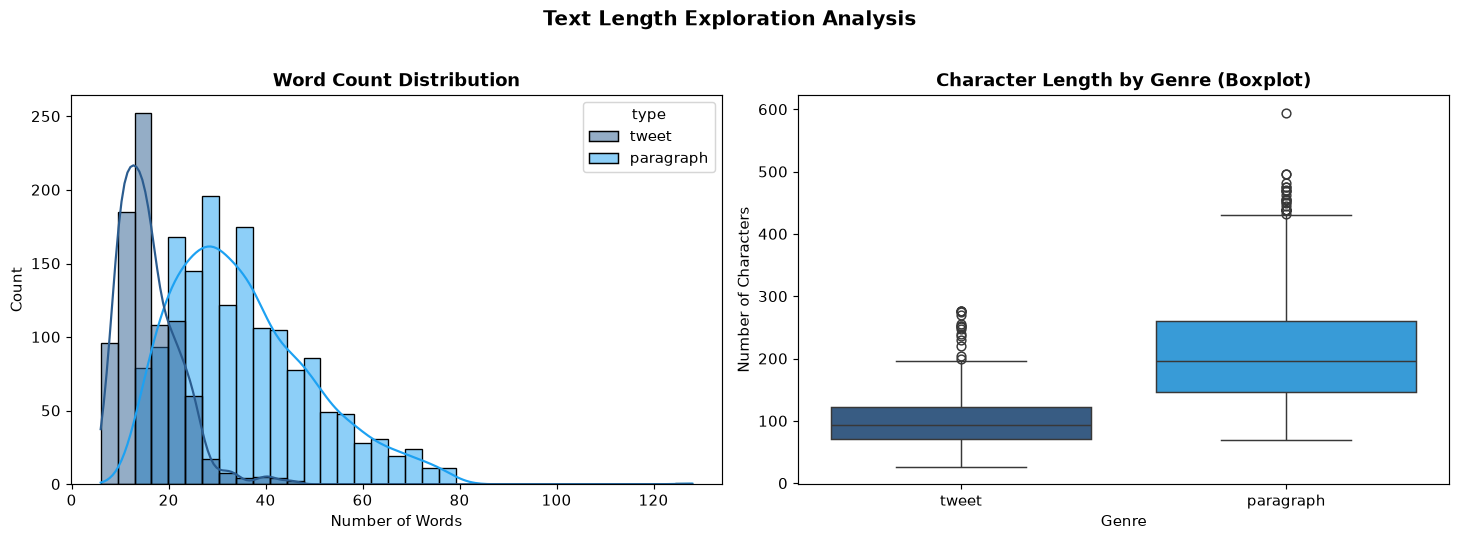

In [26]:
stats_df = explore_text_lengths(df_1b_train)